In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [2]:
df=pd.read_csv('movies_dataset.csv')
df

,MovieID,Title,Genre,ReleaseYear,ReleaseDate,Country,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,One_Week_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT,Director,LeadActor
0,1,Might toward capital,Comedy,2003,28-09-2003,China,6577427.79,6613685.82,15472035.66,1778530.85,3034053.32,6.2,58,7865,10596,Kristina Moore,Brian Mccormick
1,2,He however experience,Comedy,1988,14-02-1988,USA,1883810.10,1930949.15,3637731.12,247115.74,831828.84,5.2,44,1708,220,Benjamin Hudson,Ashley Pena
2,3,Star responsibility politics,Comedy,1971,02-11-1971,USA,2468079.29,4186694.69,7165111.24,878453.95,2171405.93,5.5,55,4678,7805,Kayla Young,Alexander Haley
3,4,Exactly live,Comedy,1998,06-08-1998,USA,1447311.46,2023683.92,4373820.26,570657.72,898886.01,7.3,87,2467,1751,Michael Ross,Patrick Barnett
4,5,Focus improve especially,Documentary,2021,17-12-2021,India,900915.86,2129629.10,3113017.38,361189.37,861775.91,6.1,67,5555,697,Faith Franklin,Duane Fletcher DDS
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999994,999995,He anyone,Action,2011,14-09-2011,China,648176.38,1075869.51,2624306.41,170212.67,614079.92,4.8,58,12664,586,Nathan Bolton,Stephanie Moore
999995,999996,Single yourself sister collection,Horror,1982,27-08-1982,USA,657167.15,1046949.86,2164587.12,119899.27,564950.72,7.3,83,622,2327,David Lee,Tracy Klein
999996,999997,Old economic,Documentary,1993,12-02-1993,USA,29914685.15,30619499.73,57774787.73,6331667.63,18136941.88,4.1,32,100,1394,Jeremy Davis,Lynn Pierce
999997,999998,My itself and leave,Horror,2013,11-11-2013,India,1382498.55,3168114.87,5567631.38,438945.44,1703606.02,4.3,23,2337,105,Melanie Olson,Melissa Mcgee


In [3]:
"""
df=pd.read_excel('file.xlsx')
"""

"\ndf=pd.read_excel('file.xlsx')\n"

In [4]:
df.head()

,MovieID,Title,Genre,ReleaseYear,ReleaseDate,Country,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,One_Week_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT,Director,LeadActor
0,1,Might toward capital,Comedy,2003,28-09-2003,China,6577427.79,6613685.82,15472035.66,1778530.85,3034053.32,6.2,58,7865,10596,Kristina Moore,Brian Mccormick
1,2,He however experience,Comedy,1988,14-02-1988,USA,1883810.10,1930949.15,3637731.12,247115.74,831828.84,5.2,44,1708,220,Benjamin Hudson,Ashley Pena
2,3,Star responsibility politics,Comedy,1971,02-11-1971,USA,2468079.29,4186694.69,7165111.24,878453.95,2171405.93,5.5,55,4678,7805,Kayla Young,Alexander Haley
3,4,Exactly live,Comedy,1998,06-08-1998,USA,1447311.46,2023683.92,4373820.26,570657.72,898886.01,7.3,87,2467,1751,Michael Ross,Patrick Barnett
4,5,Focus improve especially,Documentary,2021,17-12-2021,India,900915.86,2129629.10,3113017.38,361189.37,861775.91,6.1,67,5555,697,Faith Franklin,Duane Fletcher DDS


In [5]:
df.tail(7)

,MovieID,Title,Genre,ReleaseYear,ReleaseDate,Country,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,One_Week_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT,Director,LeadActor
999992,999993,Oil give,Thriller,2007,06-10-2007,Australia,16682276.14,18447198.25,43009421.17,4550766.66,8802922.60,5.8,72,100,719,Melissa Cohen,Amy Gomez
999993,999994,Around,Comedy,1984,04-08-1984,Japan,7400344.24,8279830.69,14528564.23,1083174.29,3875070.16,9.5,96,584,119,Mr. Drew Clark Jr.,Rodney Smith
999994,999995,He anyone,Action,2011,14-09-2011,China,648176.38,1075869.51,2624306.41,170212.67,614079.92,4.8,58,12664,586,Nathan Bolton,Stephanie Moore
999995,999996,Single yourself sister collection,Horror,1982,27-08-1982,USA,657167.15,1046949.86,2164587.12,119899.27,564950.72,7.3,83,622,2327,David Lee,Tracy Klein
999996,999997,Old economic,Documentary,1993,12-02-1993,USA,29914685.15,30619499.73,57774787.73,6331667.63,18136941.88,4.1,32,100,1394,Jeremy Davis,Lynn Pierce
999997,999998,My itself and leave,Horror,2013,11-11-2013,India,1382498.55,3168114.87,5567631.38,438945.44,1703606.02,4.3,23,2337,105,Melanie Olson,Melissa Mcgee
999998,999999,Congress federal policy,Drama,1995,09-08-1995,USA,7655641.81,18626549.48,34908325.31,4342391.46,10764341.98,6.6,60,24528,872,Albert Phillips,Samantha Sanders


In [6]:
df.loc[100:150]

,MovieID,Title,Genre,ReleaseYear,ReleaseDate,Country,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,One_Week_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT,Director,LeadActor
100,101,Hair significant fear,Drama,2004,11-10-2004,UK,7.862148e+06,4.874513e+06,9.802762e+06,1054550.57,2.019570e+06,7.7,58,1748,1944,Jeffrey Neal,Noah Harrison
101,102,Per,Drama,1996,27-04-1996,USA,3.371044e+06,3.339466e+06,6.730363e+06,672049.71,1.672743e+06,5.2,62,2688,2768,Adriana Campbell,Amy Gomez
102,103,Story when should,Sci-Fi,1982,12-08-1982,USA,3.662111e+07,9.560804e+07,1.456232e+08,9649201.26,4.776904e+07,6.0,73,2151,128,Mary Mitchell,Melissa Melendez
103,104,Market he suggest,Action,1982,23-11-1982,USA,5.206805e+06,6.929768e+06,1.630474e+07,1819017.66,3.686622e+06,6.8,49,6809,600,Michelle Collins,Amber Willis
104,105,Ever standard fill,Drama,2005,03-06-2005,USA,3.611630e+06,1.974872e+06,3.611630e+06,222872.11,1.080178e+06,8.0,77,608,50,Michael Richards,Dawn Blake
105,106,Debate clear light do,Thriller,1992,10-11-1992,USA,7.034189e+06,1.214188e+07,2.690339e+07,3054571.32,6.465380e+06,9.0,78,4973,360,David Perez,Derrick Smith
106,107,Difference sport face,Comedy,2013,14-02-2013,USA,1.836609e+07,1.800023e+07,3.123845e+07,3491028.21,1.037409e+07,5.7,47,8982,1909,Jeremy Ray,Peter Sanders
107,108,Official together sure,Thriller,2015,10-01-2015,USA,2.311365e+06,6.712540e+06,9.629497e+06,1543264.52,3.140445e+06,6.4,60,1002,82,Michelle Collins,Kristin Cook
108,109,Cut success,Drama,2000,17-04-2000,USA,1.058264e+08,2.526314e+08,4.590625e+08,53806543.21,1.411533e+08,6.8,64,12175,80,Janice Taylor,Daryl Douglas
109,110,Itself role,Comedy,2000,04-01-2000,USA,3.960233e+06,4.823338e+06,1.142218e+07,1011985.59,2.391088e+06,6.4,76,17403,50,Michael Manning,Teresa Davis


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999999 entries, 0 to 999998
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   MovieID               999999 non-null  int64  
 1   Title                 999999 non-null  object 
 2   Genre                 999999 non-null  object 
 3   ReleaseYear           999999 non-null  int64  
 4   ReleaseDate           999999 non-null  object 
 5   Country               999999 non-null  object 
 6   BudgetUSD             999999 non-null  float64
 7   US_BoxOfficeUSD       999999 non-null  float64
 8   Global_BoxOfficeUSD   999999 non-null  float64
 9   Opening_Day_SalesUSD  999999 non-null  float64
 10  One_Week_SalesUSD     999999 non-null  float64
 11  IMDbRating            999999 non-null  float64
 12  RottenTomatoesScore   999999 non-null  int64  
 13  NumVotesIMDb          999999 non-null  int64  
 14  NumVotesRT            999999 non-null  int64  
 15  

In [8]:
df.dtypes

MovieID                   int64
Title                    object
Genre                    object
ReleaseYear               int64
ReleaseDate              object
Country                  object
BudgetUSD               float64
US_BoxOfficeUSD         float64
Global_BoxOfficeUSD     float64
Opening_Day_SalesUSD    float64
One_Week_SalesUSD       float64
IMDbRating              float64
RottenTomatoesScore       int64
NumVotesIMDb              int64
NumVotesRT                int64
Director                 object
LeadActor                object
dtype: object

In [9]:
df.isnull().sum()

MovieID                 0
Title                   0
Genre                   0
ReleaseYear             0
ReleaseDate             0
Country                 0
BudgetUSD               0
US_BoxOfficeUSD         0
Global_BoxOfficeUSD     0
Opening_Day_SalesUSD    0
One_Week_SalesUSD       0
IMDbRating              0
RottenTomatoesScore     0
NumVotesIMDb            0
NumVotesRT              0
Director                0
LeadActor               0
dtype: int64

In [10]:
df.dropna(inplace=True)

In [11]:
df.duplicated().sum()

0

In [12]:
df.drop_duplicates(inplace=True)

In [13]:
df.describe()

,MovieID,ReleaseYear,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,One_Week_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT
count,999999.000000,999999.000000,9.999990e+05,9.999990e+05,9.999990e+05,9.999990e+05,9.999990e+05,999999.000000,999999.000000,999999.000000,999999.000000
mean,500000.000000,1998.001220,9.802824e+06,1.496163e+07,2.720625e+07,2.992745e+06,7.483442e+06,6.494788,64.776426,9137.184011,2031.880340
std,288674.990255,19.260863,2.249421e+07,3.879403e+07,6.954294e+07,8.132438e+06,1.955337e+07,1.485606,17.592474,24922.362780,8433.380602
min,1.000000,1950.000000,1.000000e+05,4.002547e+04,1.000000e+05,4.050470e+03,1.650742e+04,1.000000,0.000000,100.000000,50.000000
25%,250000.500000,1984.000000,1.190511e+06,1.489805e+06,2.762370e+06,2.790262e+05,7.383145e+05,5.500000,53.000000,1083.000000,119.000000
50%,500000.000000,2001.000000,3.265790e+06,4.388876e+06,8.090223e+06,8.387221e+05,2.179436e+06,6.500000,65.000000,2983.000000,405.000000
75%,749999.500000,2014.000000,9.002791e+06,1.287606e+07,2.355245e+07,2.510360e+06,6.415143e+06,7.500000,77.000000,8192.000000,1360.000000
max,999999.000000,2025.000000,3.000000e+08,1.018198e+09,1.499497e+09,2.957511e+08,5.795551e+08,10.000000,100.000000,1000000.000000,500000.000000


In [14]:
df.describe(include='object')

,Title,Genre,ReleaseDate,Country,Director,LeadActor
count,999999,999999,999999,999999,999999,999999
unique,9665,8,27757,10,150,299
top,With,Drama,24-04-2025,USA,Tara Underwood,Jeffrey Smith
freq,506,250018,93,714581,6898,6688


In [15]:
df.columns

Index(['MovieID', 'Title', 'Genre', 'ReleaseYear', 'ReleaseDate', 'Country',
       'BudgetUSD', 'US_BoxOfficeUSD', 'Global_BoxOfficeUSD',
       'Opening_Day_SalesUSD', 'One_Week_SalesUSD', 'IMDbRating',
       'RottenTomatoesScore', 'NumVotesIMDb', 'NumVotesRT', 'Director',
       'LeadActor'],
      dtype='object')

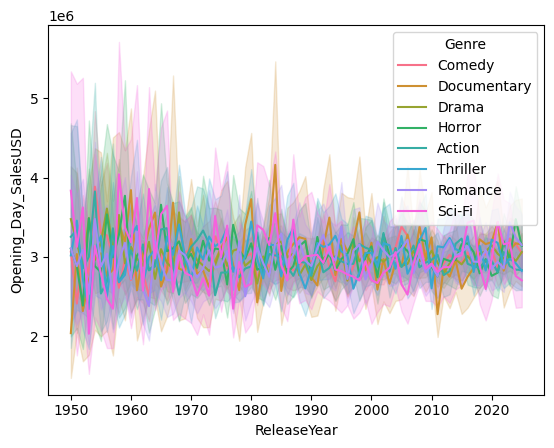

In [16]:
sns.lineplot(x='ReleaseYear',y='Opening_Day_SalesUSD',palette="husl",hue="Genre",data=df)
plt.show()

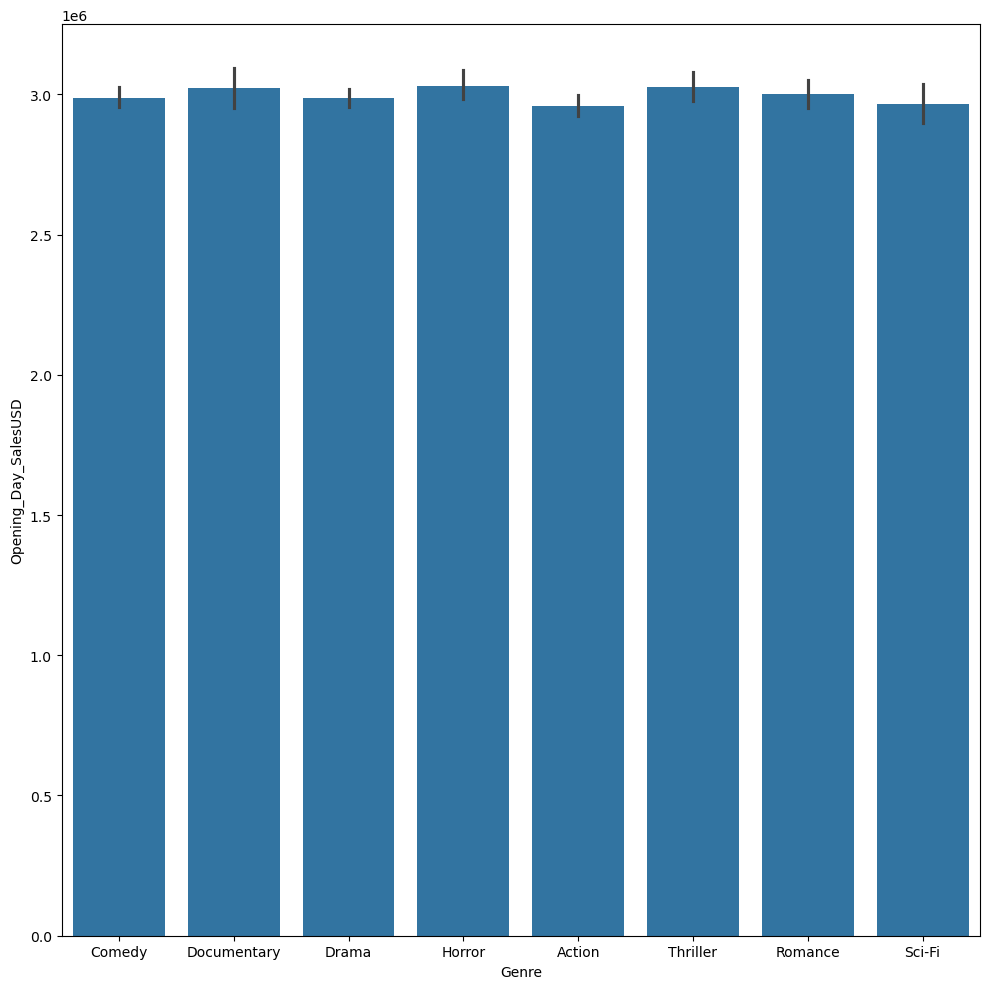

In [17]:
plt.figure(figsize=(10,10))
sns.barplot(x='Genre',y='Opening_Day_SalesUSD',data=df)
plt.tight_layout()
plt.show()

C:\Users\pantech\AppData\Local\Temp\ipykernel_2864\1858586844.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Genre',palette='Set2',data=df)


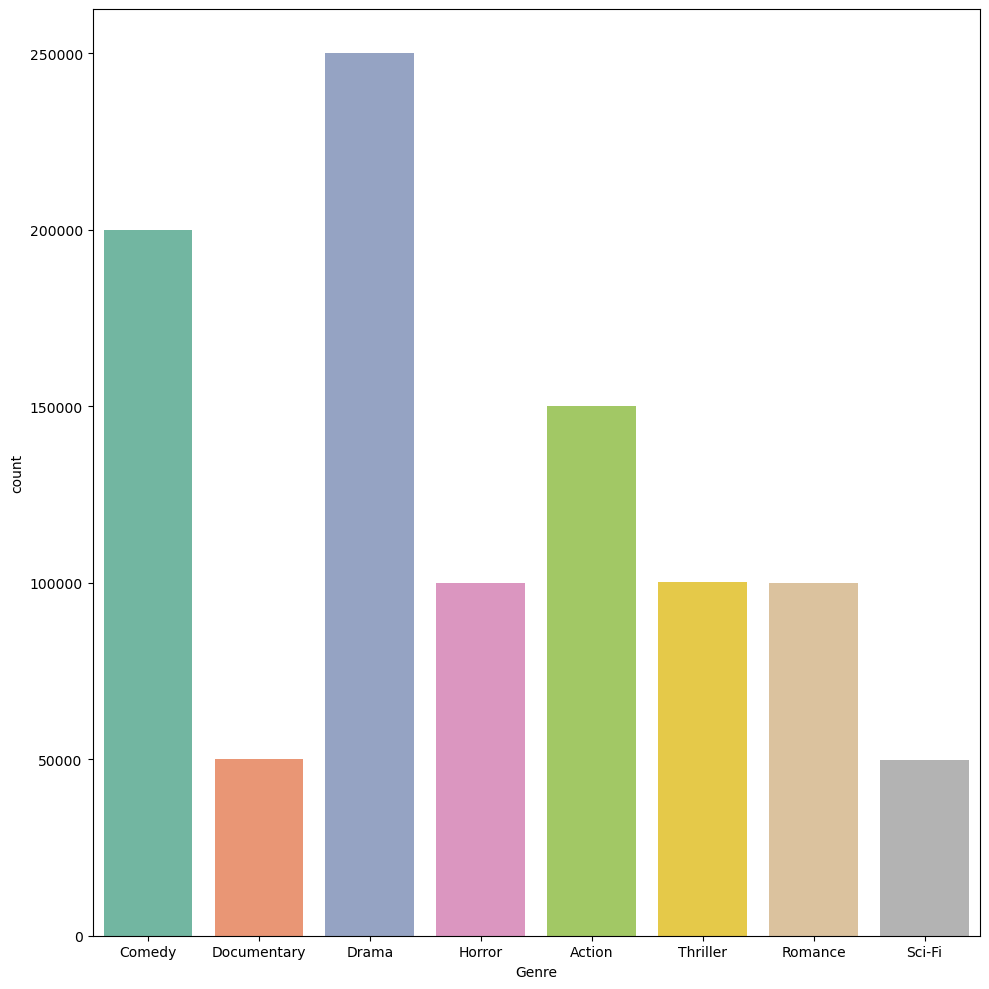

In [18]:
plt.figure(figsize=(10,10))
sns.countplot(x='Genre',palette='Set2',data=df)
plt.tight_layout()
plt.show()

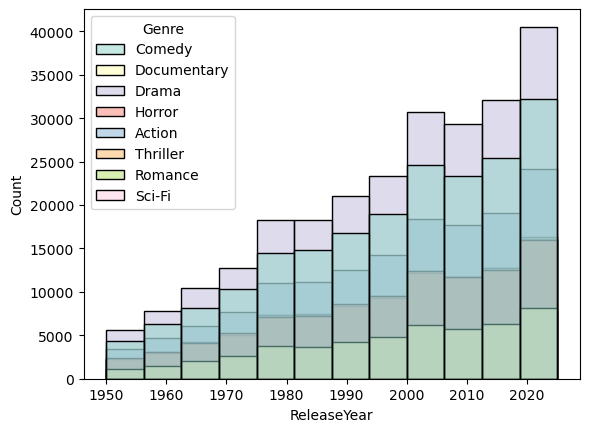

In [19]:
sns.histplot(x='ReleaseYear',bins=12,palette='Set3',hue='Genre',data=df)
plt.show()

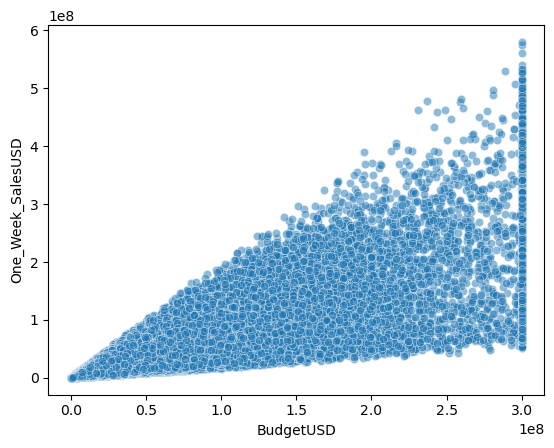

In [20]:
sns.scatterplot(x='BudgetUSD',y='One_Week_SalesUSD',alpha=0.5,data=df)
plt.show()

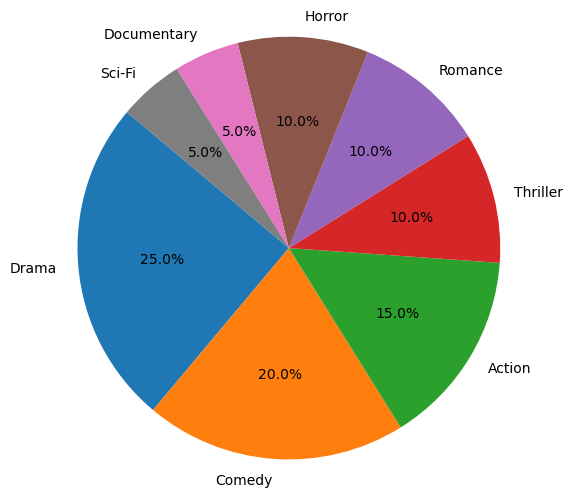

In [21]:
labels = df['Genre'].value_counts().index
sizes = df['Genre'].value_counts().values

plt.figure(figsize=(6,6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140)
plt.axis('equal')
plt.show()


In [22]:
df.columns

Index(['MovieID', 'Title', 'Genre', 'ReleaseYear', 'ReleaseDate', 'Country',
       'BudgetUSD', 'US_BoxOfficeUSD', 'Global_BoxOfficeUSD',
       'Opening_Day_SalesUSD', 'One_Week_SalesUSD', 'IMDbRating',
       'RottenTomatoesScore', 'NumVotesIMDb', 'NumVotesRT', 'Director',
       'LeadActor'],
      dtype='object')

In [23]:
df.drop('MovieID',axis=1,inplace=True)

In [24]:
df.dtypes

Title                    object
Genre                    object
ReleaseYear               int64
ReleaseDate              object
Country                  object
BudgetUSD               float64
US_BoxOfficeUSD         float64
Global_BoxOfficeUSD     float64
Opening_Day_SalesUSD    float64
One_Week_SalesUSD       float64
IMDbRating              float64
RottenTomatoesScore       int64
NumVotesIMDb              int64
NumVotesRT                int64
Director                 object
LeadActor                object
dtype: object

In [25]:
df['ReleaseDate'] = pd.to_datetime(df['ReleaseDate'], format='%d-%m-%Y')

In [26]:
df['Release_Month'] = df['ReleaseDate'].dt.month

In [27]:
df['ReleaseDate'] = df['ReleaseDate'].dt.day


In [28]:
df['Title'].unique()

array(['Might toward capital', 'He however experience',
       'Star responsibility politics', ..., 'Various', 'Cell',
       'Today they'], dtype=object)

In [29]:
df['Genre'].value_counts()

Genre
Drama          250018
Comedy         199832
Action         150131
Thriller       100071
Romance        100021
Horror         100010
Documentary     50114
Sci-Fi          49802
Name: count, dtype: int64

In [30]:
df['Director'].value_counts()

Director
Tara Underwood              6898
Melissa Hernandez           6862
Caitlin Brewer              6830
Brian Robinson              6818
Maria Lane                  6794
                            ... 
Jerry Owens                 6494
Shannon Ross                6489
Mrs. Hannah Campbell DDS    6484
Kimberly Barker             6470
Claudia Smith               6460
Name: count, Length: 150, dtype: int64

In [31]:
df['LeadActor'].value_counts()

LeadActor
Jeffrey Smith      6688
Nathan Nelson      3485
Mark Morris        3467
Michael Gomez      3463
Courtney Butler    3455
                   ... 
Ashley Gilmore     3216
Anna Vasquez       3209
Becky Dean         3197
Alan Mullins       3194
Paul Glover        3162
Name: count, Length: 299, dtype: int64

In [32]:
le=LabelEncoder()
le2=LabelEncoder()
le3=LabelEncoder()
le4=LabelEncoder()
le5=LabelEncoder()

In [33]:
df['Title']=le.fit_transform(df['Title'])
df['Genre']=le2.fit_transform(df['Genre'])
df['Director']=le3.fit_transform(df['Director'])
df['LeadActor']=le4.fit_transform(df['LeadActor'])


In [34]:
df['Country']=le5.fit_transform(df['Country'])

In [35]:
df.columns

Index(['Title', 'Genre', 'ReleaseYear', 'ReleaseDate', 'Country', 'BudgetUSD',
       'US_BoxOfficeUSD', 'Global_BoxOfficeUSD', 'Opening_Day_SalesUSD',
       'One_Week_SalesUSD', 'IMDbRating', 'RottenTomatoesScore',
       'NumVotesIMDb', 'NumVotesRT', 'Director', 'LeadActor', 'Release_Month'],
      dtype='object')

In [36]:
X=df[['Title', 'Genre', 'ReleaseYear', 'ReleaseDate', 'Country', 'BudgetUSD',
       'US_BoxOfficeUSD', 'Global_BoxOfficeUSD', 'Opening_Day_SalesUSD',
       'IMDbRating', 'RottenTomatoesScore',
       'NumVotesIMDb', 'NumVotesRT', 'Director', 'LeadActor', 'Release_Month']]
y=df['One_Week_SalesUSD']

In [37]:
X

,Title,Genre,ReleaseYear,ReleaseDate,Country,BudgetUSD,US_BoxOfficeUSD,Global_BoxOfficeUSD,Opening_Day_SalesUSD,IMDbRating,RottenTomatoesScore,NumVotesIMDb,NumVotesRT,Director,LeadActor,Release_Month
0,5069,1,2003,28,2,6577427.79,6613685.82,15472035.66,1778530.85,6.2,58,7865,10596,92,38,9
1,3656,1,1988,14,9,1883810.10,1930949.15,3637731.12,247115.74,5.2,44,1708,220,13,24,2
2,8074,1,1971,2,9,2468079.29,4186694.69,7165111.24,878453.95,5.5,55,4678,7805,87,4,11
3,2774,1,1998,6,9,1447311.46,2023683.92,4373820.26,570657.72,7.3,87,2467,1751,108,228,8
4,3153,2,2021,17,5,900915.86,2129629.10,3113017.38,361189.37,6.1,67,5555,697,53,95,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999994,3653,0,2011,14,2,648176.38,1075869.51,2624306.41,170212.67,4.8,58,12664,586,113,269,9
999995,7663,4,1982,27,9,657167.15,1046949.86,2164587.12,119899.27,7.3,83,622,2327,39,285,8
999996,5718,2,1993,12,9,29914685.15,30619499.73,57774787.73,6331667.63,4.1,32,100,1394,70,179,2
999997,5329,4,2013,11,5,1382498.55,3168114.87,5567631.38,438945.44,4.3,23,2337,105,102,195,11


In [38]:
y

0          3034053.32
1           831828.84
2          2171405.93
3           898886.01
4           861775.91
             ...     
999994      614079.92
999995      564950.72
999996    18136941.88
999997     1703606.02
999998    10764341.98
Name: One_Week_SalesUSD, Length: 999999, dtype: float64

In [39]:
X.shape

(999999, 16)

In [40]:
y.shape

(999999,)

In [41]:
X_train,X_test,y_train,y_test=train_test_split(X,y,train_size=0.8,test_size=0.2,random_state=42)

In [42]:
X_train.shape

(799999, 16)

In [43]:
X_test.shape

(200000, 16)

In [44]:
y_train.shape

(799999,)

In [45]:
y_test.shape

(200000,)

In [46]:
from sklearn.linear_model import LinearRegression

In [47]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

LinearRegression()

In [48]:
y_pred = lr_model.predict(X_test)
y_pred

array([1442613.96518331, 1727046.81048854, 1790986.39311306, ...,
       1215876.18469566, 1192923.13733498, 5336203.49587905])

In [49]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)


Mean Absolute Error (MAE): 759459.0243265512
Mean Squared Error (MSE): 6211738030585.247
Root Mean Squared Error (RMSE): 2492335.8583034603
R² Score: 0.9842301097866277


In [50]:
from sklearn.tree import DecisionTreeRegressor

In [51]:
dt_model = DecisionTreeRegressor(
    max_depth=None,        
    min_samples_split=2,
    random_state=42
)

dt_model.fit(X_train, y_train)


DecisionTreeRegressor(random_state=42)

In [52]:
y_pred_dt = dt_model.predict(X_test)


In [53]:
mae = mean_absolute_error(y_test, y_pred_dt)
mse = mean_squared_error(y_test, y_pred_dt)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_dt)

print("Decision Tree Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)


Decision Tree Results
MAE: 1015694.3366056997
MSE: 12315140642873.46
RMSE: 3509293.4677614896
R² Score: 0.968735253331014


In [54]:
import pickle
pickle.dump(le,open('title.pkl','wb'))
pickle.dump(le2,open('genre.pkl','wb'))
pickle.dump(le3,open('director.pkl','wb'))
pickle.dump(le4,open('lead_actor.pkl','wb'))
pickle.dump(le5,open('country.pkl','wb'))
pickle.dump(lr_model,open('model.pkl','wb'))